In [9]:
import pandas as pd

df = pd.read_csv('Cleaned_Dataset.csv')
recommendation_df = df.copy()

print(recommendation_df.columns.tolist())
print(recommendation_df.info())
print(recommendation_df['type'].value_counts())
print(recommendation_df.isnull().sum())
print(recommendation_df[['release_year', 'rating', 'duration']].head())

['Unnamed: 0', 'show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Unnamed: 0    8790 non-null   int64
 1   show_id       8790 non-null   str  
 2   type          8790 non-null   str  
 3   title         8790 non-null   str  
 4   director      8790 non-null   str  
 5   country       8790 non-null   str  
 6   date_added    8790 non-null   str  
 7   release_year  8790 non-null   int64
 8   rating        8790 non-null   str  
 9   duration      8790 non-null   str  
 10  listed_in     8790 non-null   str  
dtypes: int64(2), str(9)
memory usage: 755.5 KB
None
type
Movie      6126
TV Show    2664
Name: count, dtype: int64
Unnamed: 0      0
show_id         0
type            0
title           0
director        0
country         0
date_added      

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split


ml_df = recommendation_df.copy()




ml_df['release_year'] = pd.to_numeric(
    ml_df['release_year'],
    errors='coerce'
)


ml_df['duration_num'] = (
    ml_df['duration']
    .astype(str)
    .str.extract(r'(\d+)')[0]
)

ml_df['duration_num'] = pd.to_numeric(
    ml_df['duration_num'],
    errors='coerce'
)


ml_df['release_year'] = ml_df['release_year'].fillna(
    ml_df['release_year'].median()
)

ml_df['duration_num'] = ml_df['duration_num'].fillna(
    ml_df['duration_num'].median()
)

ml_df['rating'] = ml_df['rating'].fillna('Unknown')


rating_dummies = pd.get_dummies(
    ml_df['rating'],
    prefix='rating',
    dtype=int
)

# Create X
X = pd.concat([
    ml_df[['release_year', 'duration_num']],
    rating_dummies
], axis=1)

# Create target y
y = ml_df['type']

print("Features created successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Features created successfully!
X shape: (8790, 16)
y shape: (8790,)

Target classes:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 7032
Testing samples: 1758


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


logistic_model = LogisticRegression(max_iter=1000, random_state=42)

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

logistic_model.fit(X_train, y_train)

decision_tree_model.fit(X_train, y_train)

random_forest_model.fit(X_train, y_train)

print("All three models trained successfully")

All three models trained successfully


In [15]:
# Generate predictions from all three trained models

logistic_pred = logistic_model.predict(X_test)

decision_tree_pred = decision_tree_model.predict(X_test)

random_forest_pred = random_forest_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score

results = []

models_predictions = {
    "Logistic Regression": logistic_pred,
    "Decision Tree": decision_tree_pred,
    "Random Forest": random_forest_pred
}

for model_name, predictions in models_predictions.items():
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions,
        pos_label='TV Show'
    )
    recall = recall_score(
        y_test,
        predictions,
        pos_label='TV Show'
    )
    f1 = f1_score(
        y_test,
        predictions,
        pos_label='TV Show'
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    evaluation_results = pd.DataFrame(results)

    evaluation_results

In [17]:
evaluation_results_display = evaluation_results.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    evaluation_results_display[column] = (
        evaluation_results_display[column] * 100
    ).round(2)

evaluation_results_display

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,99.83,99.63,99.81,99.72
1,Decision Tree,99.72,99.62,99.44,99.53
2,Random Forest,99.77,99.62,99.62,99.62


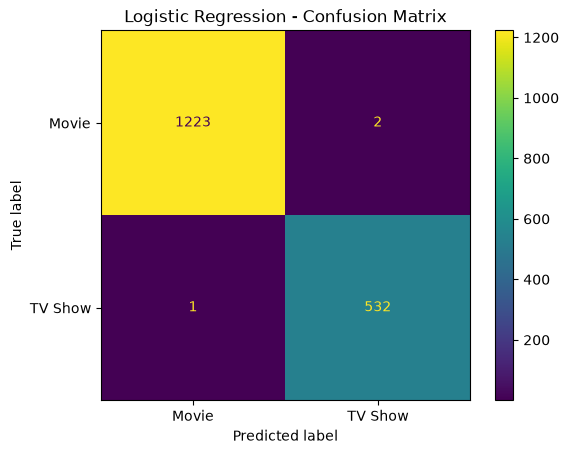

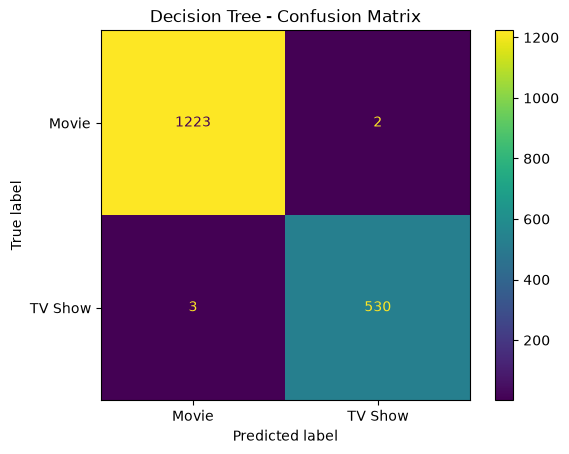

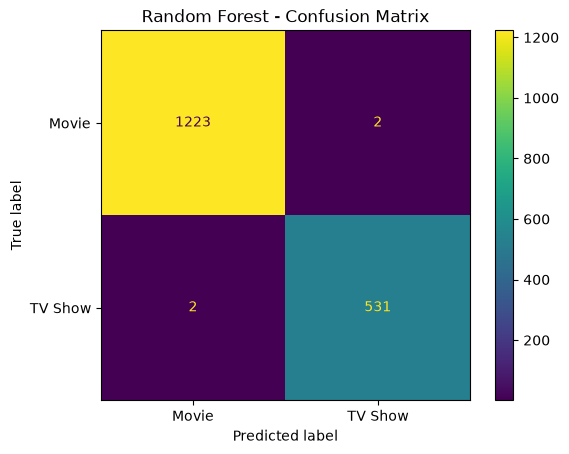

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predictions_dict = {
    "Logistic Regression": logistic_pred,
    "Decision Tree": decision_tree_pred,
    "Random Forest": random_forest_pred
}

for model_name, predictions in predictions_dict.items():
    
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=['Movie', 'TV Show']
    )
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Movie', 'TV Show']
    )
    
    disp.plot()
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

In [19]:
comparison = evaluation_results[
    ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
].copy()

for column in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    comparison[column] = (comparison[column] * 100).round(2)

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,99.83,99.63,99.81,99.72
1,Decision Tree,99.72,99.62,99.44,99.53
2,Random Forest,99.77,99.62,99.62,99.62


In [20]:
best_model = evaluation_results.loc[
    evaluation_results['Accuracy'].idxmax()
]

print("Best Model:", best_model['Model'])
print(f"Accuracy: {best_model['Accuracy'] * 100:.2f}%")
print(f"Recall: {best_model['Recall'] * 100:.2f}%")
print(f"Precision {best_model['Precision'] * 100:.2f}%")
print(f"F1-Score: {best_model['F1-Score'] * 100:.2f}%")

Best Model: Logistic Regression
Accuracy: 99.83%
Recall: 99.81%
Precision 99.63%
F1-Score: 99.72%


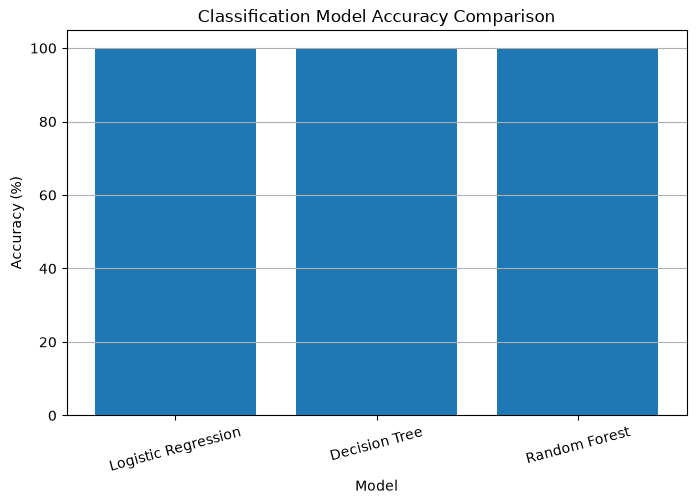

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    evaluation_results['Model'],
    evaluation_results['Accuracy'] * 100
)

plt.title('Classification Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation = 15)
plt.grid(axis='y')
plt.show()